# Exercise 4.3.31 (Impact of Regularizers)
(i) Let $N=5$ and $M = 16$. For $A \in \mathbb R^{M \times N}$ with Gaussian entries $A_{k,j} \sim M^{-1/2} \mathcal N(0,1)$ and $x_* \sim \mathcal N(0,I_N)$, we consider the noise-free inverse problem $Ax=y$.
		Implement Tikhonov regularization (see also Exercise 4.3.12) and LASSO regularizations via FISTA (Algorithm 4) for $K=10000$ iterations. 
		Plot the absolute values $|x_\alpha|$ and $\log(|x_\alpha| + 10^{-16})$ of the reconstructions $x_\alpha$ for different regularization parameters $\alpha = 10^{q}$ with $q \in [-5, 5]$. 
		What do you observe? 
		

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def fast_FBS(x0, nu, grad, prox, loss, num_iter, it_thr = 0, xt = None):
    x = x0
    func_val = np.zeros((num_iter + 1))
    func_val[0] = loss(x0) 
    z = x0
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

    for k in range(num_iter):
        x_old = x
        theta = 2.0/(2 + k)
        u = (1 - theta)*x + theta*z
        x = prox(u - nu* grad(u), nu)
        z = x_old + (x - x_old) / theta
        
        func_val[k+1] = loss(x)
        if xt is not None:
            error[k+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)
        
        if it_thr > 0 and np.linalg.norm(x - x_old) < it_thr:
            break
                
    if xt is not None:
        return x, func_val, error
    else:
        return x, func_val

In [3]:
N  = 5
M = 16
x = np.random.randn(N)
A = np.random.randn(M,N) / np.sqrt(M)
y = A @ x
x0 = np.random.randn((N))

alpha_list = 10.0**np.arange(-5,5,0.25)
X_Tikh = np.zeros((len(alpha_list), N))
X_Lasso = np.zeros((len(alpha_list), N))
num_iter = 100000

for ia in range(len(alpha_list)):    
    alph = alpha_list[ia]
    
    # Tikhonov
    grad = lambda x: A.T @( A @ x - y) + alph * x
    loss = lambda x: 0.5*np.linalg.norm(A@x - y)**2 + 0.5*alph * np.linalg.norm(x)**2
    prox = lambda x,nu: x
    nu = 1.0 / (np.linalg.norm(A,2)**2  + alph)
    
    x1, m_errors = fast_FBS(x0, 0.9*nu, grad, prox, loss,num_iter, 1e-8)
    X_Tikh[ia,:] = x1
    
    # LASSO
    grad = lambda x: A.T @( A @ x - y)
    loss = lambda x: 0.5*np.linalg.norm(A@x - y)**2 + alph * np.linalg.norm(x,1)
    prox = lambda x,nu: np.sign(x)*np.maximum(np.abs(x) - nu*alph, 0)
    nu = 1.0 / np.linalg.norm(A,2)**2
    x2, m_errors = fast_FBS(x0, 0.9*nu, grad, prox, loss,num_iter, 1e-8)
    X_Lasso[ia,:] = x2

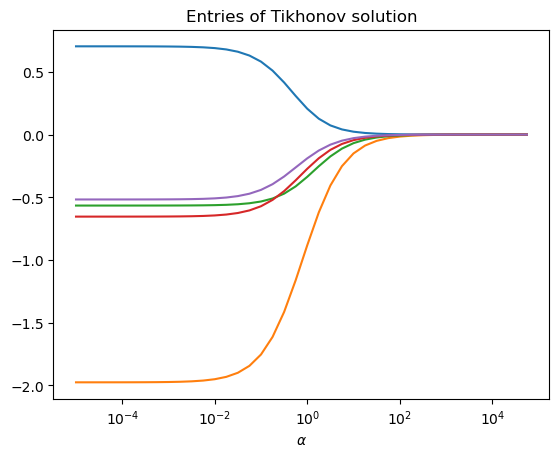

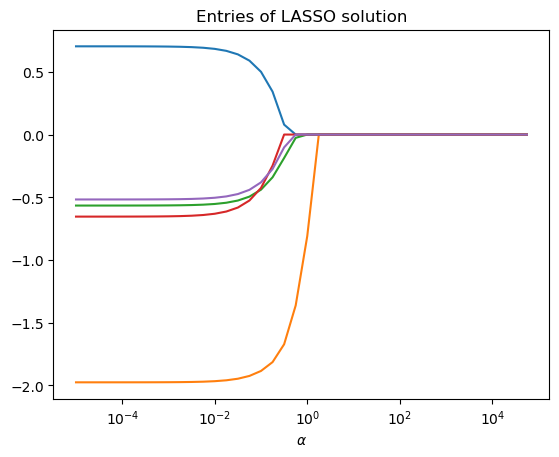

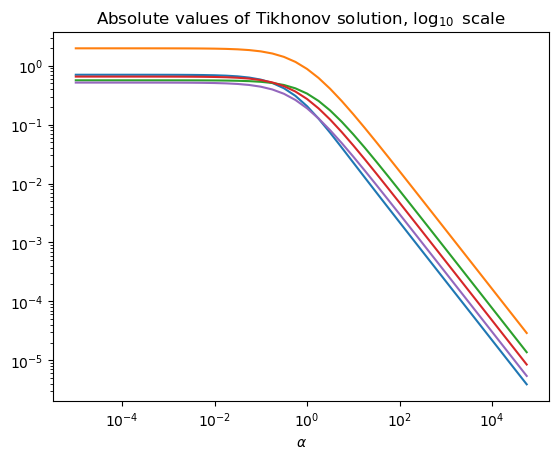

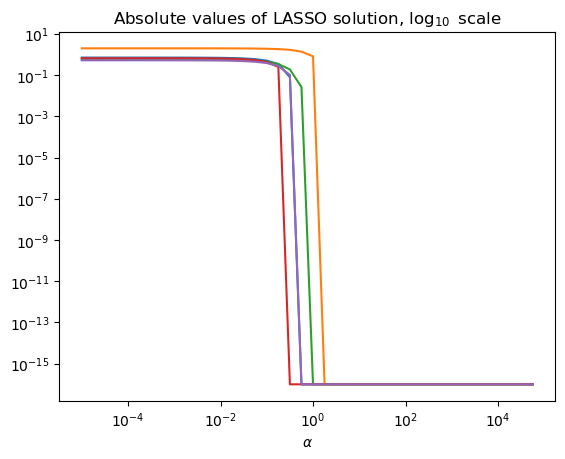

In [4]:
plt.semilogx(alpha_list,X_Tikh)
plt.title(r'Entries of Tikhonov solution')
plt.xlabel(r"$\alpha$")
plt.show()

plt.semilogx(alpha_list,X_Lasso)
plt.title(r'Entries of LASSO solution')
plt.xlabel(r"$\alpha$")
plt.show()


plt.loglog(alpha_list,1e-16 + np.abs(X_Tikh))
plt.title(r'Absolute values of Tikhonov solution, $\log_{10}$ scale')
plt.xlabel(r"$\alpha$")
plt.show()

plt.loglog(alpha_list,1e-16 + np.abs(X_Lasso))
plt.title(r'Absolute values of LASSO solution, $\log_{10}$ scale')
plt.xlabel(r"$\alpha$")
plt.show()


(ii) Load the $28 \times 28$ image \texttt{10104.png} from the MNIST dataset https://github.com/rasbt/mnist-pngs/blob/main/train/4/10104.png and convert it to a vector $x_* \in \mathbb R^{748}$. For $M \in [160, 380]$, consider the inverse problems from (i). To obtain a reconstruction, minimize the LASSO and Tikhonov functional with $\alpha = 10^{-1}$ and $\alpha = 10^{-2}$, respectively. Visualize the reconstructions for different $M$ (as images).

784

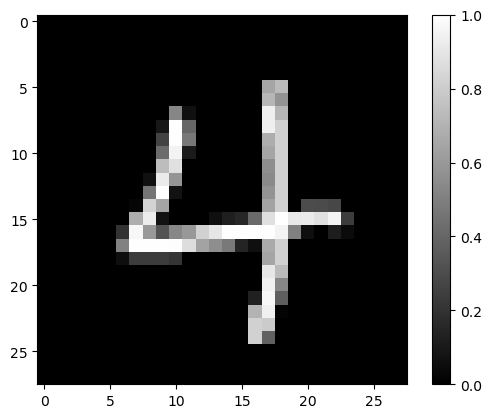

In [5]:
# source: https://github.com/rasbt/mnist-pngs/tree/main
img = plt.imread('imgs/10104.png')

plt.imshow(img, cmap = 'grey')
plt.colorbar()

np.prod(img.shape)

In [6]:
x = img.flatten()

N  = len(x)
M_list = np.arange(160,400,20)
X_Tikh = np.zeros((len(M_list), N))
X_Lasso = np.zeros((len(M_list), N))
num_iter = 1000

def show_rec(X, title = '', rows = 3):
    L = X.shape[0] # 12
    fig, axs = plt.subplots(rows, L//rows)
    fig.suptitle('Reconsturctions '+ title)
    for ix in range(rows):
        for iy in range(L//rows):
            im_rec  = np.reshape(X[ix*rows + iy,:], img.shape)
            plot = axs[ix, iy].imshow(im_rec, vmin=0, vmax=1)
            axs[ix, iy].set_title('M: ' + str(M_list[ix* L//rows + iy]))
            axs[ix, iy].axis("off")
    
    fig.subplots_adjust(right=0.8)
    cbar_ax = fig.add_axes([0.85, 0.15, 0.05, 0.7])
    fig.colorbar(plot, cax=cbar_ax)

for im in range(len(M_list)):    
    print('Progress: ',im + 1, ' our of ', len(M_list))
    M = M_list[im]
    A = np.random.randn(M,N) / np.sqrt(M)
    y = A @ x
    x0 = np.random.randn((N))
    
    alph = 1*1e-2
    
    # Tikhonov
    grad = lambda x: A.T @( A @ x - y) + alph * x
    loss = lambda x: 0.5*np.linalg.norm(A@x - y)**2 + 0.5*alph * np.linalg.norm(x)**2
    prox = lambda x,nu: x
    nu = 1.0 / (np.linalg.norm(A,2)**2  + alph)
    
    x1, m_errors = fast_FBS(x0, 0.9*nu, grad, prox, loss,num_iter, 1e-8)
    X_Tikh[im,:] = x1

    alph = 1*1e-1
    
    # LASSO
    grad = lambda x: A.T @( A @ x - y)
    loss = lambda x: 0.5*np.linalg.norm(A@x - y)**2 + alph * np.linalg.norm(x,1)
    prox = lambda x,nu: np.sign(x)*np.maximum(np.abs(x) - nu*alph, 0)
    nu = 1.0 / np.linalg.norm(A,2)**2
    x2, m_errors = fast_FBS(x0, 0.9*nu, grad, prox, loss,num_iter, 1e-8)
    X_Lasso[im,:] = x2

Progress:  1  our of  12
Progress:  2  our of  12
Progress:  3  our of  12
Progress:  4  our of  12
Progress:  5  our of  12
Progress:  6  our of  12
Progress:  7  our of  12
Progress:  8  our of  12
Progress:  9  our of  12
Progress:  10  our of  12
Progress:  11  our of  12
Progress:  12  our of  12


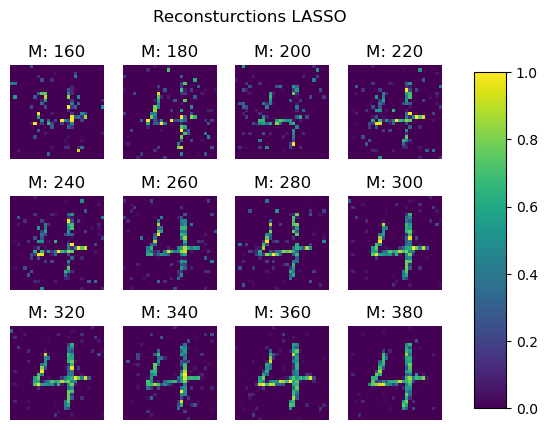

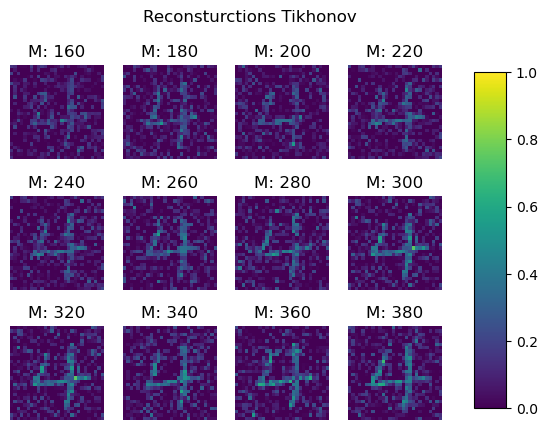

In [7]:
def show_rec(X, title = '', rows = 3):
    L = X.shape[0] # 12
    fig, axs = plt.subplots(rows, L//rows)
    fig.suptitle('Reconsturctions '+ title)
    for ix in range(rows):
        for iy in range(L//rows):
            im_rec  = np.reshape(X[ix*rows + iy,:], img.shape)
            plot = axs[ix, iy].imshow(im_rec, vmin=0, vmax=1)
            axs[ix, iy].set_title('M: ' + str(M_list[ix* L//rows + iy]))
            axs[ix, iy].axis("off")
    
    fig.subplots_adjust(right=0.8)
    cbar_ax = fig.add_axes([0.85, 0.15, 0.05, 0.7])
    fig.colorbar(plot, cax=cbar_ax)
    
show_rec(X_Lasso, 'LASSO')
show_rec(X_Tikh, 'Tikhonov')